WARNING    'w' is an internal variable of group 'synapses_10', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_11', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_12', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_13', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_14', but also exists in the run namespace with the value 6. The internal variable will be used. [brian

Starting simulation at t=0. s for a duration of 10. s
[1000 ms]  rates (mean): 61.0 Hz  
[1000 ms]  rates (mean): 14.2 Hz  
[1100 ms]  rates (mean): 61.6 Hz  
[1100 ms]  rates (mean): 14.5 Hz  
[1200 ms]  rates (mean): 61.6 Hz  
[1200 ms]  rates (mean): 14.5 Hz  
[1300 ms]  rates (mean): 61.2 Hz  
[1300 ms]  rates (mean): 13.9 Hz  
[1400 ms]  rates (mean): 60.4 Hz  
[1400 ms]  rates (mean): 13.2 Hz  
[1500 ms]  rates (mean): 59.5 Hz  
[1500 ms]  rates (mean): 12.3 Hz  
[1600 ms]  rates (mean): 58.7 Hz  
[1600 ms]  rates (mean): 12.0 Hz  
[1700 ms]  rates (mean): 57.9 Hz  
[1700 ms]  rates (mean): 11.1 Hz  
1.7001 s (17%) simulated in 10s, estimated 53s remaining.
[1800 ms]  rates (mean): 56.7 Hz  
[1800 ms]  rates (mean): 10.3 Hz  
[1900 ms]  rates (mean): 55.2 Hz  
[1900 ms]  rates (mean): 9.0 Hz  
[2000 ms]  rates (mean): 53.7 Hz  
[2000 ms]  rates (mean): 8.1 Hz  
[2100 ms]  rates (mean): 52.4 Hz  
[2100 ms]  rates (mean): 7.5 Hz  
[2200 ms]  rates (mean): 50.6 Hz  
[2200 ms]  rates

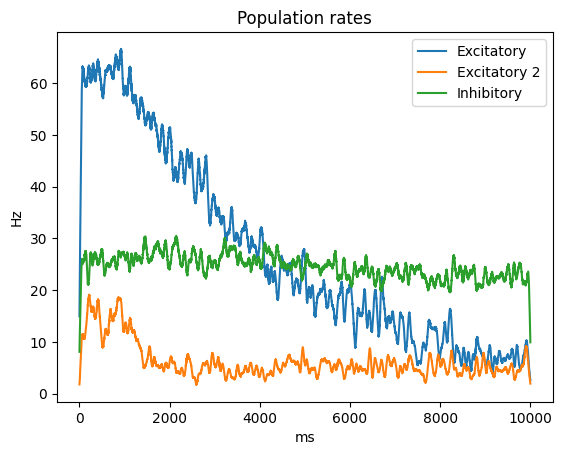

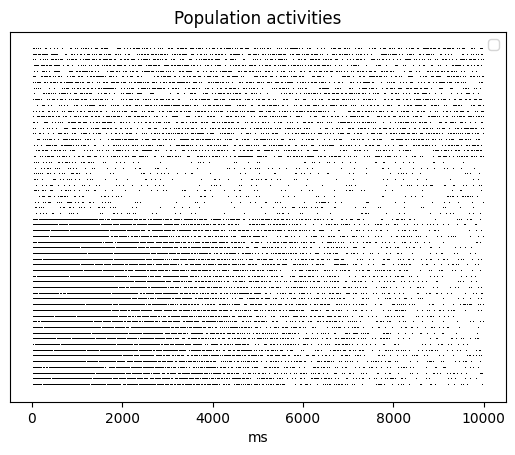

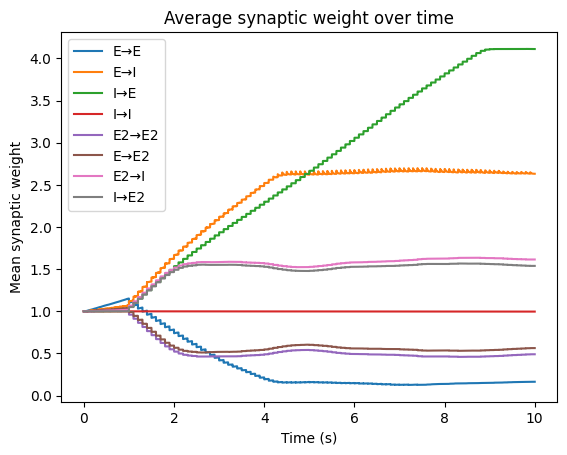

WARNING    /tmp/ipykernel_5053/3679828931.py:433: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_5053/3679828931.py:434: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)

WARNING    /tmp/ipykernel_5053/3679828931.py:435: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword 

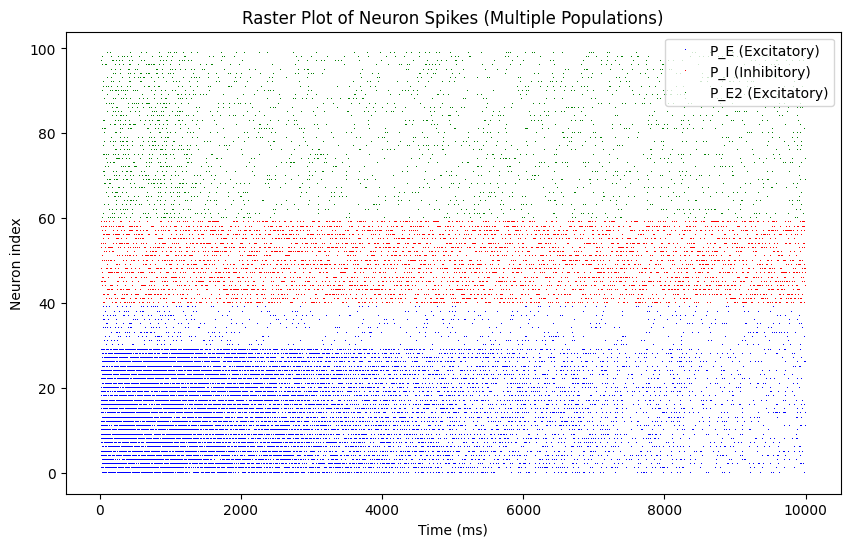

WARNING    /tmp/ipykernel_5053/3679828931.py:471: DeprecationWarning: scipy.signal.cwt is deprecated in SciPy 1.12 and will be removed
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E1 = cwt(rate_E1, morlet2, widths, w=w)
 [py.warnings]
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E1 = cwt(rate_E1, morlet2, widths, w=w)

WARNING    /tmp/ipykernel_5053/3679828931.py:472: DeprecationWarning: scipy.signal.cwt is deprecated in SciPy 1.12 and will be removed
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E2 = cwt(rate_E2, morlet2, widths, w=w)
 [py.warnings]
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E2 = cwt(rate_E2, morlet2, widths, w=w)



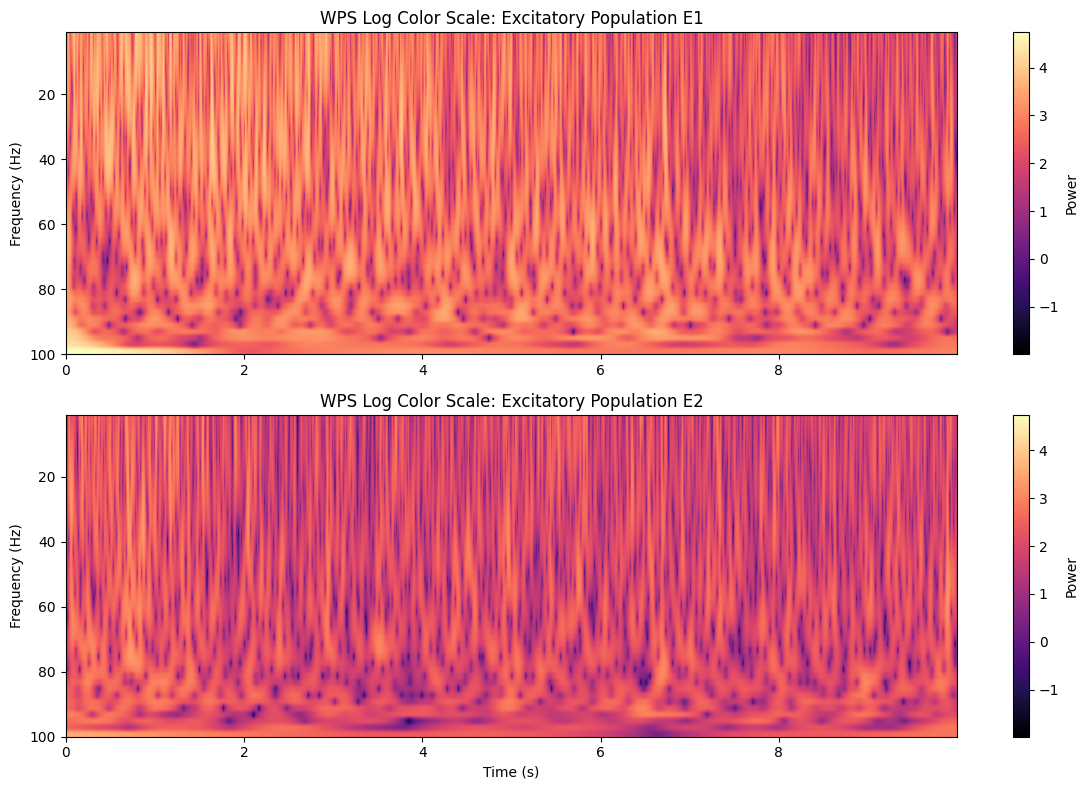

In [2]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import spectrogram
from scipy.signal import cwt, morlet2


start_scope()

#gif 
save_interval = 0.1*second  
frames = []
def plot_weights_for_gif(t):
    # Build a full weight matrix from Synapses (N_E x N_E)
    W = np.zeros((N_E, N_E))
    for i, j, w_ij in zip(C_E_E.i[:], C_E_E.j[:], C_E_E.w[:]):
        W[i, j] = w_ij
    
    plt.figure(figsize=(6, 6))
    plt.imshow(W, cmap='hot', interpolation='nearest')
    plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
    plt.colorbar(label='Weight')
    plt.xlabel('Post-synaptic neuron')
    plt.ylabel('Pre-synaptic neuron')

    frame = plt.gcf()
    frames.append(frame)
    plt.close()

# Phase durations
simu_duration = 10 * second


pattern_neurons = np.arange(30)  
pattern_rate = 5*Hz  

# populations
N = 100
N_E = int(N * 0.4)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 5*Hz
alpha = 0.05 #0.1
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 0.8*nS #1.25 * nS 
g_GABA_I = 0.8*nS #0.973 * nS 
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_E2 = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E2.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


# eqs_pre_glut = '''
# s_AMPA += w
# '''

# eqs_pre_gaba = '''
# s_GABA += w
# '''
#STDP
stdp_eqs = '''
w : 1
dpre/dt = -pre/ taupre : 1 (event-driven)
dpost/dt = -post/ taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''


Apre = 0.012
Apost = -0.01 
w_max = 3.0
on_pre_stdp = '''
s_AMPA += w
pre += 1.
w = clip(w + Apost * post, 0, w_max)
'''

on_post_stdp = '''
post += 1.
w = clip(w + Apre * pre, 0, w_max)
'''
#iSTDP
Apre_i = -0.005   
Apost_i = 0.005
w_max_i = 5.0
iSTDP_eqs = '''
w : 1
dpre/dt = -pre / taupre : 1 (event-driven)
dpost/dt = -post / taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

on_pre_iSTDP = '''
s_GABA += w
pre += 1.
w = clip(w + Apost_i * post, 0, w_max_i)
'''

on_post_iSTDP = '''
post += 1.
w = clip(w + Apre_i * pre, 0, w_max_i)
'''


#E1
# E to E
C_E_E = Synapses(P_E, P_E,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
C_E_E.taupre = 20*ms
C_E_E.taupost = 20*ms

# E to I
C_E_I = Synapses(P_E, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_I.connect()
C_E_I.w[:] = 1
C_E_I.taupre = 20*ms
C_E_I.taupost = 20*ms

# I to I
C_I_I = Synapses(P_I, P_I,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1
C_I_I.taupre = 20*ms
C_I_I.taupost = 20*ms

# I to E
C_I_E = Synapses(P_I, P_E,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E.connect()
C_I_E.w[:] = 1
C_I_E.taupre = 20*ms
C_I_E.taupost = 20*ms

#E2
# E1 to E2
C_E_E2 = Synapses(P_E, P_E2,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E2.connect('i != j')
C_E_E2.w[:] = 1
C_E_E2.taupre = 20*ms
C_E_E2.taupost = 20*ms

# E2 to E2
C_E2_E2 = Synapses(P_E2, P_E2,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E2_E2.connect('i != j')
C_E2_E2.w[:] = 1
C_E2_E2.taupre = 20*ms
C_E2_E2.taupost = 20*ms


# E2 to I
C_E2_I = Synapses(P_E2, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E2_I.connect('i != j')
C_E2_I.w[:] = 1
C_E2_I.taupre = 20*ms
C_E2_I.taupost = 20*ms

# I to E2
C_I_E2 = Synapses(P_I, P_E2,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E2.connect()
C_I_E2.w[:] = 1
C_I_E2.taupre = 20*ms
C_I_E2.taupost = 20*ms

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_E2 = PoissonInput(P_E2, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')

#pattern
C_select=C_ext/4
total_duration = simu_duration
dt = 100*ms
stim_array = np.zeros(int(total_duration/dt))
stim_array[:int(simu_duration/dt)] = 1
stimuli = TimedArray(stim_array, dt=dt)
pattern_input = PoissonInput(P_E[pattern_neurons], 's_AMPA_ext', C_select, pattern_rate, 'stimuli(t)')


# monitors

sp_E = SpikeMonitor(P_E)
sp_E2 = SpikeMonitor(P_E2)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_E2 = PopulationRateMonitor(P_E2)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)
mon_C_E_E2 = StateMonitor(C_E_E2, 'w', record=True)
mon_C_E2_E2 = StateMonitor(C_E2_E2, 'w', record=True)
mon_C_E2_I = StateMonitor(C_E2_I, 'w', record=True)
mon_C_I_E2 = StateMonitor(C_I_E2, 'w', record=True)

# @network_operation(dt=save_interval)
# def capture_frames():
#     plot_weights_for_gif(defaultclock.t)


@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    #E
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    #E2
    times = sp_E2.t
    idxs  = sp_E2.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E2_E2.w[pre, post] = clip(C_E2_E2.w[pre, post]+ alpha * delta, 0, 5)
            C_E_E2.w[pre,post] = clip(C_E_E2.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E2.w[pre, post] = clip(C_I_E2.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E2_I.w[post, pre] = clip(C_E2_I.w[post, pre] - alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
 
    # times1 = sp_E.t
    # idxs1  = sp_E.i
    # rates1 = np.zeros(N_E)*Hz
    # times2 = sp_E2.t
    # idxs2  = sp_E2.i
    # rates2 = np.zeros(N_E)*Hz
    # for post in range(N_E):  #+ N_E
    #     mask1 = np.logical_and(idxs1 == post, times1 >= t0)
    #     mask2 = np.logical_and(idxs2 == post, times2 >= t0)
    #     count1 = np.sum(mask1)
    #     count2 = np.sum(mask2)
    #     rates1[post] = count1 / window
    #     rates2[post] = count2 / window
    # avg_rate_E1 = np.mean(rates1) 
    # avg_rate_E2 = np.mean(rates2)
    # avg_rate_E= (avg_rate_E1+avg_rate_E2)/2
    # C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)



net = Network(collect())
net.run(simu_duration, report='stdout') # 

# def create_gif():
#     # Convert saved frames to GIF
#     gif_filename = 'weight_connections.gif'
#     with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
#         for frame in frames:
#             # Convert the figure to an image
#             image_path = 'temp_frame.png'
#             frame.savefig(image_path)
#             image = imageio.imread(image_path)
#             writer.append_data(image)
#             os.remove(image_path)  # Remove the temporary image after adding it to the GIF
    
#     print(f"GIF saved as {gif_filename}")
# create_gif()


# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_E2.t / ms, r_E2.smooth_rate(width=25 * ms) / Hz, label='Excitatory 2')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()



def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plot_mean_weight(mon_C_E2_E2, 'E2→E2')
plot_mean_weight(mon_C_E_E2, 'E→E2')
plot_mean_weight(mon_C_E2_I, 'E2→I')
plot_mean_weight(mon_C_I_E2, 'I→E2')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.plot(sp_E2.t / ms, sp_E2.i + N_E+N_I, ',k', label='P_E2 (Excitatory)', color='green', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()


# 1. Convert spike times into population rates (1 ms bins)
bin_size = 1 * ms
duration_ms = int((simu_duration) / ms)
bins = np.arange(0, duration_ms + 1, bin_size/ms)

def get_population_rate(spike_monitor, N_neurons, bins):
    spike_times = spike_monitor.t / ms
    hist, _ = np.histogram(spike_times, bins=bins)
    rate = hist / (N_neurons * (bin_size / second))  # Normalize to Hz
    return rate

rate_E1 = get_population_rate(sp_E, N_E, bins)
rate_E2 = get_population_rate(sp_E2, N_E, bins)
time_axis = bins[:-1] / 1000  # seconds
fs = 1000  # Hz (since bin is 1 ms)

# Define wavelet frequency scales
num_freqs = 50
min_freq = 1  # Hz
max_freq = 100  # Hz
frequencies = np.linspace(min_freq, max_freq, num_freqs)

# Convert frequencies to widths (scale) for Morlet wavelet
# Width = fs * w / (2 * pi * f)
w = 6  # Wavelet width (cycles); 5-7 is standard
widths = fs * w / (2 * np.pi * frequencies)

# Compute CWT
cwt_E1 = cwt(rate_E1, morlet2, widths, w=w)
cwt_E2 = cwt(rate_E2, morlet2, widths, w=w)

cwt_E1_log = np.log10(np.abs(cwt_E1)**2 + 1e-2)  
cwt_E2_log = np.log10(np.abs(cwt_E2)**2 + 1e-2)

log_power_min = min(np.min(cwt_E1_log), np.min(cwt_E2_log)) 
log_power_max = max(np.max(cwt_E1_log), np.max(cwt_E2_log))  

plt.figure(figsize=(12, 8))

# E1
plt.subplot(2, 1, 1)
plt.imshow(cwt_E1_log, aspect='auto', extent=[0, time_axis[-1], max_freq, min_freq],
           cmap='magma', origin='lower', vmin=log_power_min, vmax=log_power_max)
plt.title('WPS Log Color Scale: Excitatory Population E1')
plt.ylabel('Frequency (Hz)')
plt.colorbar(label='Power')

# E2
plt.subplot(2, 1, 2)
plt.imshow(cwt_E2_log, aspect='auto', extent=[0, time_axis[-1], max_freq, min_freq],
           cmap='magma', origin='lower', vmin=log_power_min, vmax=log_power_max)
plt.title('WPS Log Color Scale: Excitatory Population E2')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.colorbar(label='Power')

plt.tight_layout()
plt.show()

With Inhibition HSP

WARNING    'w' is an internal variable of group 'synapses_1', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_5', but also exists in the run namespace with the value 6. The internal variable will be used. [brian2.gro

Starting simulation at t=0. s for a duration of 10. s
[1000 ms]  rates (mean): 60.4 Hz  
[1000 ms]  rates (mean): 15.2 Hz  
[1100 ms]  rates (mean): 60.1 Hz  
[1100 ms]  rates (mean): 15.0 Hz  
[1200 ms]  rates (mean): 58.9 Hz  
[1200 ms]  rates (mean): 13.9 Hz  
[1300 ms]  rates (mean): 56.2 Hz  
[1300 ms]  rates (mean): 12.7 Hz  
1.3001 s (13%) simulated in 10s, estimated 1m 8s remaining.
[1400 ms]  rates (mean): 53.3 Hz  
[1400 ms]  rates (mean): 11.2 Hz  
[1500 ms]  rates (mean): 49.9 Hz  
[1500 ms]  rates (mean): 9.7 Hz  
[1600 ms]  rates (mean): 46.1 Hz  
[1600 ms]  rates (mean): 8.2 Hz  
[1700 ms]  rates (mean): 42.2 Hz  
[1700 ms]  rates (mean): 6.7 Hz  
[1800 ms]  rates (mean): 38.7 Hz  
[1800 ms]  rates (mean): 4.8 Hz  
[1900 ms]  rates (mean): 34.2 Hz  
[1900 ms]  rates (mean): 3.5 Hz  
[2000 ms]  rates (mean): 30.1 Hz  
[2000 ms]  rates (mean): 1.8 Hz  
[2100 ms]  rates (mean): 26.2 Hz  
[2100 ms]  rates (mean): 0.8 Hz  
[2200 ms]  rates (mean): 22.6 Hz  
[2200 ms]  rates (

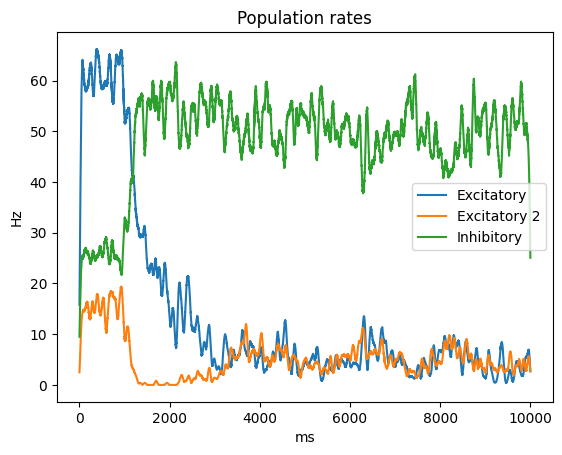

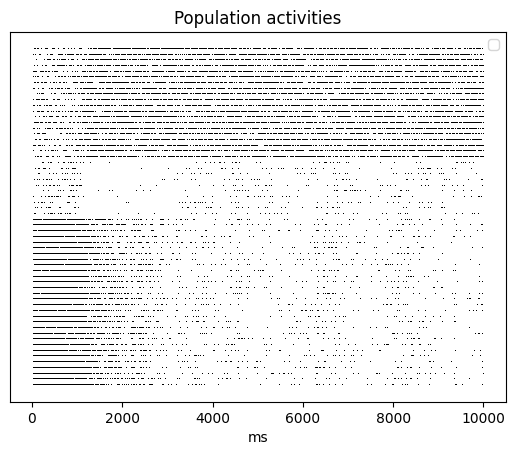

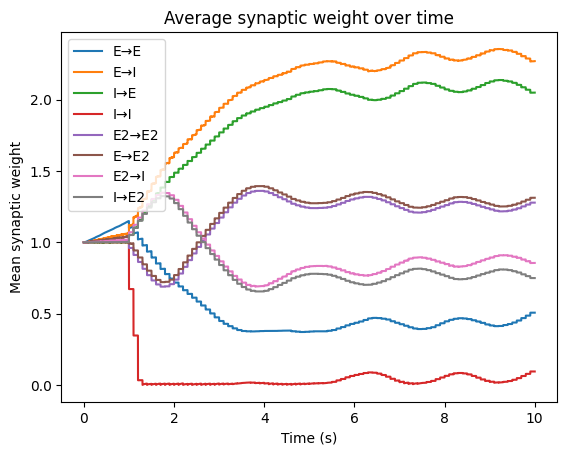

WARNING    /tmp/ipykernel_5053/4050460935.py:433: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_5053/4050460935.py:434: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)

WARNING    /tmp/ipykernel_5053/4050460935.py:435: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword 

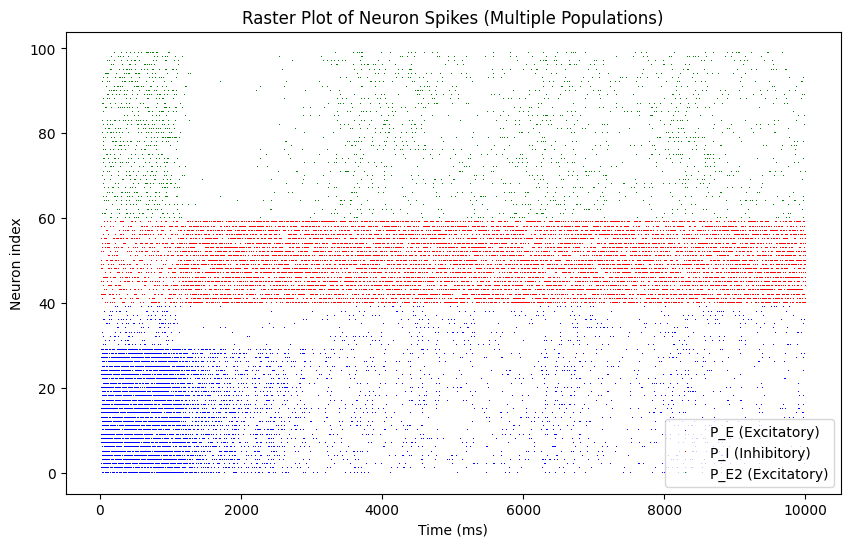

WARNING    /tmp/ipykernel_5053/4050460935.py:471: DeprecationWarning: scipy.signal.cwt is deprecated in SciPy 1.12 and will be removed
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E1 = cwt(rate_E1, morlet2, widths, w=w)
 [py.warnings]
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E1 = cwt(rate_E1, morlet2, widths, w=w)

WARNING    /tmp/ipykernel_5053/4050460935.py:472: DeprecationWarning: scipy.signal.cwt is deprecated in SciPy 1.12 and will be removed
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E2 = cwt(rate_E2, morlet2, widths, w=w)
 [py.warnings]
in SciPy 1.15. We recommend using PyWavelets instead.

  cwt_E2 = cwt(rate_E2, morlet2, widths, w=w)



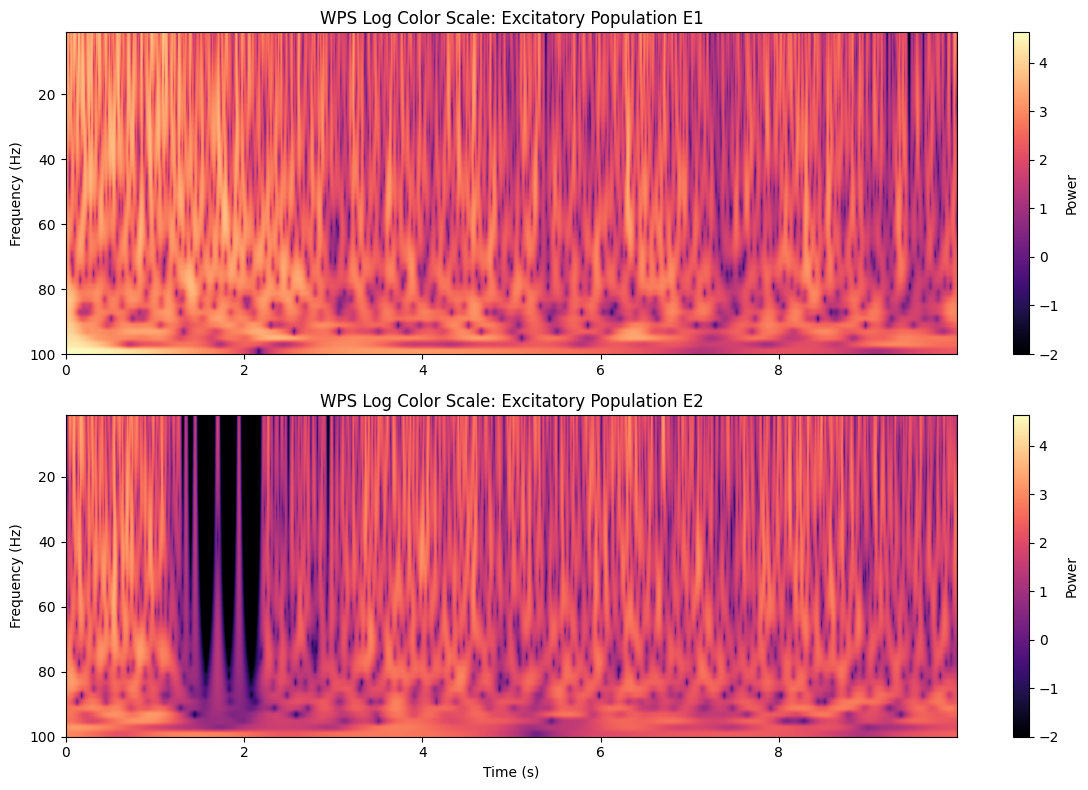

In [3]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import spectrogram
from scipy.signal import cwt, morlet2


start_scope()

#gif 
save_interval = 0.1*second  
frames = []
def plot_weights_for_gif(t):
    # Build a full weight matrix from Synapses (N_E x N_E)
    W = np.zeros((N_E, N_E))
    for i, j, w_ij in zip(C_E_E.i[:], C_E_E.j[:], C_E_E.w[:]):
        W[i, j] = w_ij
    
    plt.figure(figsize=(6, 6))
    plt.imshow(W, cmap='hot', interpolation='nearest')
    plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
    plt.colorbar(label='Weight')
    plt.xlabel('Post-synaptic neuron')
    plt.ylabel('Pre-synaptic neuron')

    frame = plt.gcf()
    frames.append(frame)
    plt.close()

# Phase durations
simu_duration = 10 * second


pattern_neurons = np.arange(30)  
pattern_rate = 5*Hz  

# populations
N = 100
N_E = int(N * 0.4)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 5*Hz
alpha = 0.05 #0.1
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 0.8*nS #1.25 * nS 
g_GABA_I = 0.8*nS #0.973 * nS 
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_E2 = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E2.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


# eqs_pre_glut = '''
# s_AMPA += w
# '''

# eqs_pre_gaba = '''
# s_GABA += w
# '''
#STDP
stdp_eqs = '''
w : 1
dpre/dt = -pre/ taupre : 1 (event-driven)
dpost/dt = -post/ taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''


Apre = 0.012
Apost = -0.01 
w_max = 3.0
on_pre_stdp = '''
s_AMPA += w
pre += 1.
w = clip(w + Apost * post, 0, w_max)
'''

on_post_stdp = '''
post += 1.
w = clip(w + Apre * pre, 0, w_max)
'''
#iSTDP
Apre_i = -0.005   
Apost_i = 0.005
w_max_i = 5.0
iSTDP_eqs = '''
w : 1
dpre/dt = -pre / taupre : 1 (event-driven)
dpost/dt = -post / taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

on_pre_iSTDP = '''
s_GABA += w
pre += 1.
w = clip(w + Apost_i * post, 0, w_max_i)
'''

on_post_iSTDP = '''
post += 1.
w = clip(w + Apre_i * pre, 0, w_max_i)
'''


#E1
# E to E
C_E_E = Synapses(P_E, P_E,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
C_E_E.taupre = 20*ms
C_E_E.taupost = 20*ms

# E to I
C_E_I = Synapses(P_E, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_I.connect()
C_E_I.w[:] = 1
C_E_I.taupre = 20*ms
C_E_I.taupost = 20*ms

# I to I
C_I_I = Synapses(P_I, P_I,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1
C_I_I.taupre = 20*ms
C_I_I.taupost = 20*ms

# I to E
C_I_E = Synapses(P_I, P_E,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E.connect()
C_I_E.w[:] = 1
C_I_E.taupre = 20*ms
C_I_E.taupost = 20*ms

#E2
# E1 to E2
C_E_E2 = Synapses(P_E, P_E2,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E2.connect('i != j')
C_E_E2.w[:] = 1
C_E_E2.taupre = 20*ms
C_E_E2.taupost = 20*ms

# E2 to E2
C_E2_E2 = Synapses(P_E2, P_E2,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E2_E2.connect('i != j')
C_E2_E2.w[:] = 1
C_E2_E2.taupre = 20*ms
C_E2_E2.taupost = 20*ms


# E2 to I
C_E2_I = Synapses(P_E2, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E2_I.connect('i != j')
C_E2_I.w[:] = 1
C_E2_I.taupre = 20*ms
C_E2_I.taupost = 20*ms

# I to E2
C_I_E2 = Synapses(P_I, P_E2,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E2.connect()
C_I_E2.w[:] = 1
C_I_E2.taupre = 20*ms
C_I_E2.taupost = 20*ms

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_E2 = PoissonInput(P_E2, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')

#pattern
C_select=C_ext/4
total_duration = simu_duration
dt = 100*ms
stim_array = np.zeros(int(total_duration/dt))
stim_array[:int(simu_duration/dt)] = 1
stimuli = TimedArray(stim_array, dt=dt)
pattern_input = PoissonInput(P_E[pattern_neurons], 's_AMPA_ext', C_select, pattern_rate, 'stimuli(t)')


# monitors

sp_E = SpikeMonitor(P_E)
sp_E2 = SpikeMonitor(P_E2)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_E2 = PopulationRateMonitor(P_E2)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)
mon_C_E_E2 = StateMonitor(C_E_E2, 'w', record=True)
mon_C_E2_E2 = StateMonitor(C_E2_E2, 'w', record=True)
mon_C_E2_I = StateMonitor(C_E2_I, 'w', record=True)
mon_C_I_E2 = StateMonitor(C_I_E2, 'w', record=True)

# @network_operation(dt=save_interval)
# def capture_frames():
#     plot_weights_for_gif(defaultclock.t)


@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    #E
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    #E2
    times = sp_E2.t
    idxs  = sp_E2.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E2_E2.w[pre, post] = clip(C_E2_E2.w[pre, post]+ alpha * delta, 0, 5)
            C_E_E2.w[pre,post] = clip(C_E_E2.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E2.w[pre, post] = clip(C_I_E2.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E2_I.w[post, pre] = clip(C_E2_I.w[post, pre] - alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
 
    times1 = sp_E.t
    idxs1  = sp_E.i
    rates1 = np.zeros(N_E)*Hz
    times2 = sp_E2.t
    idxs2  = sp_E2.i
    rates2 = np.zeros(N_E)*Hz
    for post in range(N_E):  #+ N_E
        mask1 = np.logical_and(idxs1 == post, times1 >= t0)
        mask2 = np.logical_and(idxs2 == post, times2 >= t0)
        count1 = np.sum(mask1)
        count2 = np.sum(mask2)
        rates1[post] = count1 / window
        rates2[post] = count2 / window
    avg_rate_E1 = np.mean(rates1) 
    avg_rate_E2 = np.mean(rates2)
    avg_rate_E= (avg_rate_E1+avg_rate_E2)/2
    C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)



net = Network(collect())
net.run(simu_duration, report='stdout') # 

# def create_gif():
#     # Convert saved frames to GIF
#     gif_filename = 'weight_connections.gif'
#     with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
#         for frame in frames:
#             # Convert the figure to an image
#             image_path = 'temp_frame.png'
#             frame.savefig(image_path)
#             image = imageio.imread(image_path)
#             writer.append_data(image)
#             os.remove(image_path)  # Remove the temporary image after adding it to the GIF
    
#     print(f"GIF saved as {gif_filename}")
# create_gif()


# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_E2.t / ms, r_E2.smooth_rate(width=25 * ms) / Hz, label='Excitatory 2')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()



def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plot_mean_weight(mon_C_E2_E2, 'E2→E2')
plot_mean_weight(mon_C_E_E2, 'E→E2')
plot_mean_weight(mon_C_E2_I, 'E2→I')
plot_mean_weight(mon_C_I_E2, 'I→E2')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.plot(sp_E2.t / ms, sp_E2.i + N_E+N_I, ',k', label='P_E2 (Excitatory)', color='green', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()


# 1. Convert spike times into population rates (1 ms bins)
bin_size = 1 * ms
duration_ms = int((simu_duration) / ms)
bins = np.arange(0, duration_ms + 1, bin_size/ms)

def get_population_rate(spike_monitor, N_neurons, bins):
    spike_times = spike_monitor.t / ms
    hist, _ = np.histogram(spike_times, bins=bins)
    rate = hist / (N_neurons * (bin_size / second))  # Normalize to Hz
    return rate

rate_E1 = get_population_rate(sp_E, N_E, bins)
rate_E2 = get_population_rate(sp_E2, N_E, bins)
time_axis = bins[:-1] / 1000  # seconds
fs = 1000  # Hz (since bin is 1 ms)

# Define wavelet frequency scales
num_freqs = 50
min_freq = 1  # Hz
max_freq = 100  # Hz
frequencies = np.linspace(min_freq, max_freq, num_freqs)

# Convert frequencies to widths (scale) for Morlet wavelet
# Width = fs * w / (2 * pi * f)
w = 6  # Wavelet width (cycles); 5-7 is standard
widths = fs * w / (2 * np.pi * frequencies)

# Compute CWT
cwt_E1 = cwt(rate_E1, morlet2, widths, w=w)
cwt_E2 = cwt(rate_E2, morlet2, widths, w=w)

cwt_E1_log = np.log10(np.abs(cwt_E1)**2 + 1e-2)  
cwt_E2_log = np.log10(np.abs(cwt_E2)**2 + 1e-2)

log_power_min = min(np.min(cwt_E1_log), np.min(cwt_E2_log)) 
log_power_max = max(np.max(cwt_E1_log), np.max(cwt_E2_log))  

plt.figure(figsize=(12, 8))

# E1
plt.subplot(2, 1, 1)
plt.imshow(cwt_E1_log, aspect='auto', extent=[0, time_axis[-1], max_freq, min_freq],
           cmap='magma', origin='lower', vmin=log_power_min, vmax=log_power_max)
plt.title('WPS Log Color Scale: Excitatory Population E1')
plt.ylabel('Frequency (Hz)')
plt.colorbar(label='Power')

# E2
plt.subplot(2, 1, 2)
plt.imshow(cwt_E2_log, aspect='auto', extent=[0, time_axis[-1], max_freq, min_freq],
           cmap='magma', origin='lower', vmin=log_power_min, vmax=log_power_max)
plt.title('WPS Log Color Scale: Excitatory Population E2')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.colorbar(label='Power')

plt.tight_layout()
plt.show()